# Morris-Lecar Model
Exploring the Morris-Lecar model of a biological neuron.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from brian2 import *
%matplotlib inline

## 1. Morris-Lecar Equations
The Morris-Lecar model incorporates calcium and potassium channels.

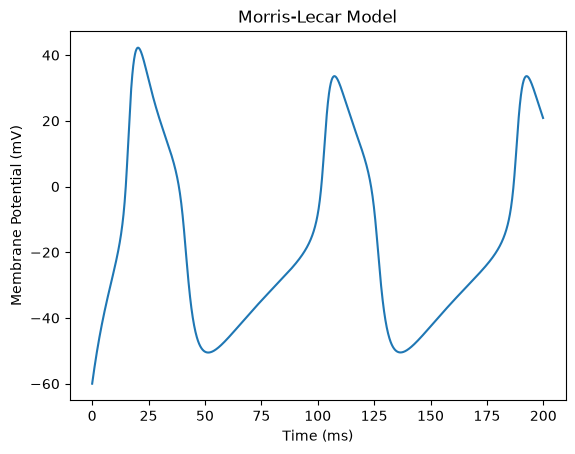

In [2]:
start_scope()
C = 20*ufarad*cm**-2
g_Ca = 4.4*msiemens*cm**-2
g_K = 8*msiemens*cm**-2
g_L = 2*msiemens*cm**-2
V_Ca = 120*mV
V_K = -84*mV
V_L = -60*mV
V1 = -1.2*mV
V2 = 18*mV
V3 = 2*mV
V4 = 30*mV
phi_n = 0.04*ms**-1
I = 100*uA*cm**-2

eqs = '''
dV/dt = (I - g_Ca * M_ss * (V - V_Ca) - g_K * n_var * (V - V_K) - g_L * (V - V_L)) / C : volt
dn_var/dt = phi_n * (n_ss - n_var) / tau_n_var : 1
M_ss = 0.5 * (1 + tanh((V - V1) / V2)) : 1
n_ss = 0.5 * (1 + tanh((V - V3) / V4)) : 1
tau_n_var = 1.0 / cosh((V - V3) / (2 * V4)) : 1
'''

neuron = NeuronGroup(1, eqs, method='euler')
neuron.V = V_L
neuron.n_var = 0

statemon = StateMonitor(neuron, 'V', record=True)
run(200*ms)

plt.plot(statemon.t/ms, statemon.V[0]/mV)
plt.xlabel('Time (ms)')
plt.ylabel('Membrane Potential (mV)')
plt.title('Morris-Lecar Model')
plt.show()
